# Prediction intervals for individual treatment effects

A confidence interval for the conditional average effect $\tau(x) = E[Y(1) - Y(0) \mid X = x]$ says
how precisely a *mean* is known. A unit's own effect $Y(1) - Y(0)$ also varies with everything
that $X$ does not capture. With enough data the confidence interval for $\tau(x)$ shrinks to a
point, but the spread of individual effects does not.

`dml_rs.ConformalITE` gives **prediction intervals** for the potential outcomes and the individual
effect of a new unit (Lei and Candès, 2021). They contain the unit's value with probability
$1 - \alpha$ under unconfoundedness. They come from weighted split conformal prediction:

1. Split the sample. Fit the outcome learners and the propensity score on the training part.
2. For each arm, compute conformity scores on the calibration units: absolute residuals
   $|Y - \hat\mu(X)|$, or with conformalised quantile regression,
   $\max(\hat q_{lo}(X) - Y,\ Y - \hat q_{hi}(X))$.
3. The calibration units of arm $w$ come from $X \mid D = w$, not from the target population.
   So their scores are reweighted by the likelihood ratio, e.g. $1 / e(x)$ for $Y(1)$ over all
   units (weighted conformal prediction under covariate shift). The interval is the prediction
   plus or minus a weighted quantile of the scores.

With a known propensity score, coverage holds in finite samples. With an estimated one it holds
approximately. This notebook uses simulated data, where the true individual effects are known.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor

import dml_rs

pd.set_option("display.precision", 3)


def simulate(n, rng):
    X = rng.uniform(-1, 1, size=(n, 5))
    e = 0.25 + 0.5 / (1 + np.exp(-3 * X[:, 0]))  # propensity score
    D = (rng.random(n) < e).astype(float)
    mu0 = X[:, 1] + np.sin(np.pi * X[:, 0])
    tau = 1 + X[:, 0]  # conditional average effect
    sd = 0.2 + 0.8 * np.abs(X[:, 0])  # noise grows with |x_0|
    Y0 = mu0 + sd * rng.normal(size=n)
    Y1 = mu0 + tau + sd * rng.normal(size=n)
    return X, D, np.where(D == 1, Y1, Y0), Y1, Y0, tau


X, D, Y, _, _, _ = simulate(4000, np.random.default_rng(0))
X_new, D_new, _, Y1_new, Y0_new, tau_new = simulate(
    5000, np.random.default_rng(1)
)
ite_new = Y1_new - Y0_new


def covered(intervals, truth):
    return (intervals[:, 0] <= truth) & (truth <= intervals[:, 1])


def coverage(intervals, truth):
    return pd.Series(
        {
            "coverage": covered(intervals, truth).mean(),
            "median width": np.median(intervals[:, 1] - intervals[:, 0]),
        }
    )

## Two conformity scores

`ml_y` gives the residual score, with intervals $\hat\mu_w(x) \pm Q$ of nearly the same width
everywhere (only the weights vary with $x$).
`ml_lower` and `ml_upper` give conformalised quantile regression. Here the learners are
scikit-learn's quantile gradient boosting at the 5% and 95% quantiles, and the intervals adapt to
the noise. In both cases `ml_m` estimates the propensity score.

In [2]:
residual = dml_rs.ConformalITE(
    ml_m=dml_rs.LogisticRegression(),
    ml_y=dml_rs.RandomForestRegressor(
        n_estimators=200, min_samples_leaf=10
    ),
).fit(X, Y, D)

quantile = dml_rs.ConformalITE(
    ml_m=dml_rs.LogisticRegression(),
    ml_lower=GradientBoostingRegressor(
        loss="quantile", alpha=0.05, n_estimators=200, max_depth=3
    ),
    ml_upper=GradientBoostingRegressor(
        loss="quantile", alpha=0.95, n_estimators=200, max_depth=3
    ),
).fit(X, Y, D)
print(
    "calibration units per arm (control, treated):",
    residual.n_calibration_,
)

calibration units per arm (control, treated): [495, 505]


`predict_counterfactual` gives intervals for one potential outcome. `predict_ite` combines the
intervals of $Y(1)$ and $Y(0)$ at level $\alpha/2$ each into $[L_1 - U_0, U_1 - L_0]$. That
guarantees $1 - \alpha$ coverage of the individual effect, but conservatively. Check both on 5,000 new
units at $\alpha = 0.1$:

In [3]:
pd.DataFrame(
    {
        "Y(1), residual": coverage(
            residual.predict_counterfactual(X_new, treatment=1), Y1_new
        ),
        "Y(1), quantile": coverage(
            quantile.predict_counterfactual(X_new, treatment=1), Y1_new
        ),
        "ITE, residual": coverage(residual.predict_ite(X_new), ite_new),
        "ITE, quantile": coverage(quantile.predict_ite(X_new), ite_new),
    }
).T

,coverage,median width
"Y(1), residual",0.906,2.284
"Y(1), quantile",0.909,2.322
"ITE, residual",0.992,5.815
"ITE, quantile",0.995,5.238


The intervals for $Y(1)$ cover 90% of the new units, as targeted. The effect intervals cover more
than 90%, as the combination implies.

## Adapting to the noise

Overall coverage hides how it is spread. The noise grows with $|x_0|$. The residual score's
intervals have nearly the same width everywhere, so they over-cover where the noise is small and
under-cover where it is large. The quantile score's intervals follow the noise:

In [4]:
bins = pd.cut(np.abs(X_new[:, 0]), [0, 0.25, 0.5, 0.75, 1.0])
rows = {}
for name, model in {"residual": residual, "quantile": quantile}.items():
    iv = model.predict_counterfactual(X_new, treatment=1)
    rows[(name, "coverage")] = (
        pd.Series(covered(iv, Y1_new)).groupby(bins, observed=True).mean()
    )
    rows[(name, "width")] = (
        pd.Series(iv[:, 1] - iv[:, 0])
        .groupby(bins, observed=True)
        .median()
    )
pd.DataFrame(rows).rename_axis("|x_0|")

residual        quantile       
            coverage  width coverage  width
|x_0|                                      
(0.0, 0.25]    0.998  2.284    0.909  1.169
(0.25, 0.5]    0.976  2.284    0.933  1.991
(0.5, 0.75]    0.882  2.323    0.909  2.588
(0.75, 1.0]    0.766  2.284    0.885  2.981

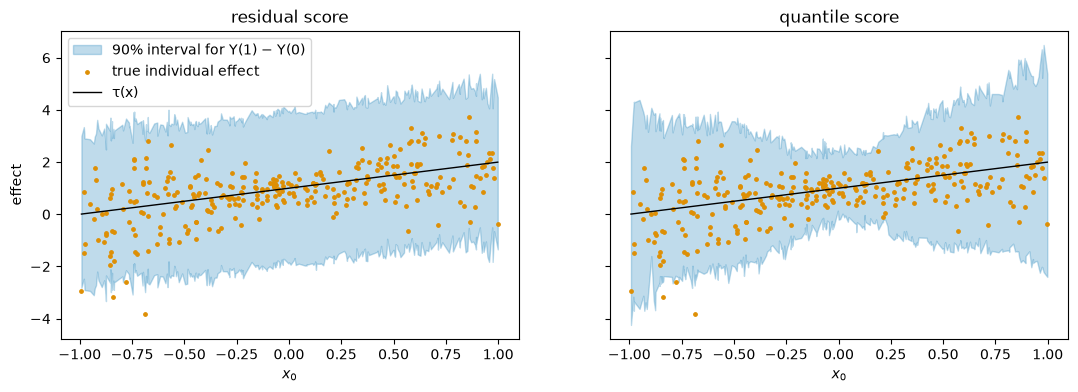

In [5]:
order = np.argsort(X_new[:300, 0])
x0 = X_new[:300, 0][order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, model) in zip(
    axes, {"residual score": residual, "quantile score": quantile}.items()
):
    iv = model.predict_ite(X_new[:300])[order]
    ax.fill_between(
        x0,
        iv[:, 0],
        iv[:, 1],
        color="#0173B2",
        alpha=0.25,
        label="90% interval for Y(1) − Y(0)",
    )
    ax.scatter(
        x0,
        ite_new[:300][order],
        s=6,
        color="#DE8F05",
        label="true individual effect",
    )
    ax.plot(x0, tau_new[:300][order], color="black", lw=1, label="τ(x)")
    ax.set_title(name)
    ax.set_xlabel("$x_0$")
axes[0].set_ylabel("effect")
axes[0].legend(loc="upper left");

## Prediction intervals are not confidence intervals

A causal forest gives confidence intervals for $\tau(x)$. They are narrow, and they cover $\tau(x)$,
but they are not meant to cover the individual effects:

In [6]:
forest = dml_rs.CausalForest(
    dml_rs.RandomForestRegressor(n_estimators=200, min_samples_leaf=10),
    dml_rs.RandomForestClassifier(n_estimators=200, min_samples_leaf=10),
).fit(X, Y, D)
cate_ci = forest.effect_interval(X_new, level=0.9)
ite_iv = quantile.predict_ite(X_new)
pd.DataFrame(
    {
        "covers τ(x)": [
            covered(cate_ci, tau_new).mean(),
            covered(ite_iv, tau_new).mean(),
        ],
        "covers Y(1) − Y(0)": [
            covered(cate_ci, ite_new).mean(),
            covered(ite_iv, ite_new).mean(),
        ],
        "median width": [
            np.median(np.diff(cate_ci)),
            np.median(np.diff(ite_iv)),
        ],
    },
    index=[
        "causal forest 90% CI for τ(x)",
        "conformal 90% interval for the ITE",
    ],
)

,covers τ(x),covers Y(1) − Y(0),median width
causal forest 90% CI for τ(x),0.902,0.189,0.378
conformal 90% interval for the ITE,1.000,0.995,5.238


Use confidence intervals for $\tau(x)$ to learn how the *average* effect varies. Use prediction
intervals to say what may happen to a *particular* unit, for example whether a unit's effect could
be negative.

## Other populations

`target` chooses the population that the new units come from: `"all"` (default), `"treated"` or
`"control"`. For example, `Y(0)` for units like the treated ones is the counterfactual outcome of
treated units, the quantity behind the effect on the treated:

In [7]:
treated_new = D_new == 1
coverage(
    quantile.predict_counterfactual(
        X_new[treated_new], treatment=0, target="treated"
    ),
    Y0_new[treated_new],
)

coverage        0.912
median width    2.146
dtype: float64

## Summary

- `ConformalITE` gives prediction intervals for $Y(1)$, $Y(0)$ and $Y(1) - Y(0)$ of new units.
  `alpha` sets the miscoverage and `target` the population.
- Prefer the quantile score (`ml_lower`, `ml_upper`) when the noise varies with $X$. The residual
  score (`ml_y`) is faster and fine with homoscedastic noise.
- In a randomised experiment, pass `propensity=` (the known treatment probability) instead of `ml_m`.
  Coverage is then exact in finite samples.
- `train_fraction` (default 0.75) trades the learners' accuracy against the number of calibration
  units. A fitted model holds its learners and is not picklable.